In [2]:
from matplotlib.colors import LogNorm
import seaborn as sns
import numpy as np
import pandas as pd
from utils import repeat, df_vals, melt_and_keep
from sparse_recov import plot_on_facets, perform_least_squares_fit, add_fit_lines_to_plot
import matplotlib.pyplot as plt
from ydata_profiling import ProfileReport


In [3]:
df= pd.read_pickle("../data/jan_2025_21.pickle")
profile = ProfileReport(df, title="Profiling Report")
profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [4]:
thetime = df['runtime_seconds'].describe()
maxtime = thetime.mean() + thetime.std()
(15*60)/maxtime

np.float64(1.2297600160975648)

In [5]:
df_vals(df)

'm':
[   100    240    575   1379   3306   7928  19012  45589 109321 262144]
----------------------------------------
'k':
[  5  30 100]
----------------------------------------
'sigma':
[0.    0.001 0.01  0.1   0.3   1.   ]
----------------------------------------
'img':
Categorical:  ['camera']
Categories (2, object): ['phantom', 'camera']
----------------------------------------
'sampling_type':
Categorical:  ['wr']
Categories (2, object): ['wr', 'Ber']
----------------------------------------
'adapted_sampling':
[ True False]
----------------------------------------
'alg':
- bpdn
- bpdn_projected
----------------------------------------
'seed':
min: 6630402.00, max: 4294811504.00, mean: 2212312528.39, std: 1261448579.06
----------------------------------------
're':
min: 0.00, max: 1390242.14, mean: 2676.48, std: 49822.53
----------------------------------------
'runtime_seconds':
min: 0.10, max: 65.24, mean: 5.16, std: 8.71
----------------------------------------
'indices':
unhas

/Users/matthewscott/Prog/Sparse_adapted_denoising/venv/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


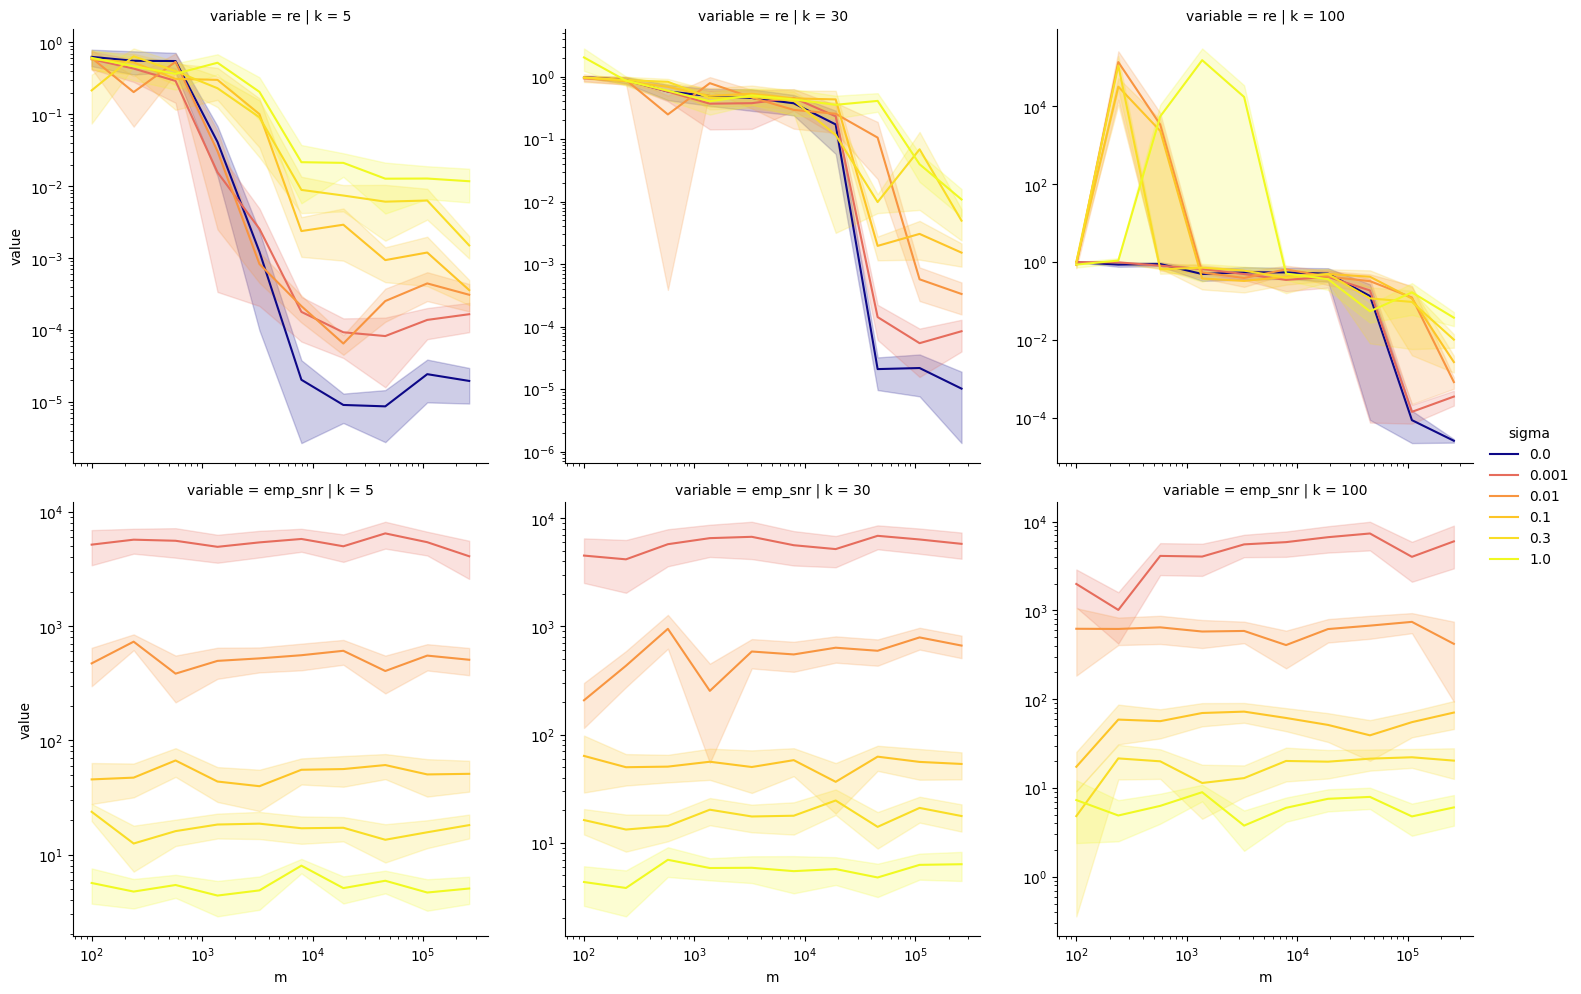

In [6]:
# df_wr = df[df['sampling_type']=='wr']
# mydf = df_wr[df_wr['adapted_sampling']==True]
# mydf = df_wr[mydf['img']=="phantom"]
%matplotlib inline
mydf=df
doubledf = melt_and_keep(mydf, ["re","emp_snr"])
g = sns.relplot(doubledf, kind = "line", x = "m", y="value", row ="variable", col="k", hue="sigma", hue_norm=LogNorm(vmin=1e-8, clip=True) , palette="plasma", errorbar="se", facet_kws={'sharey':False})
for ax in g.axes.flat:
    ax.set_yscale('log')  # Set y-axis to log scale
plt.xscale("log")
# g=sns.relplot(mydf, kind = "line", x = "m", y="re", col="k", row="lambda_"  , hue="sigma", hue_norm=LogNorm(vmin=1e-4, clip=True), palette="plasma", errorbar="se", facet_kws={'sharey':False})
#doubledf=melt_and_keep(mydf, ["re","unique_meas"])

/Users/matthewscott/Prog/Sparse_adapted_denoising/sparse_recov/sampling_recov_functions.py:41: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  groups = df_filtered.groupby(group_cols)


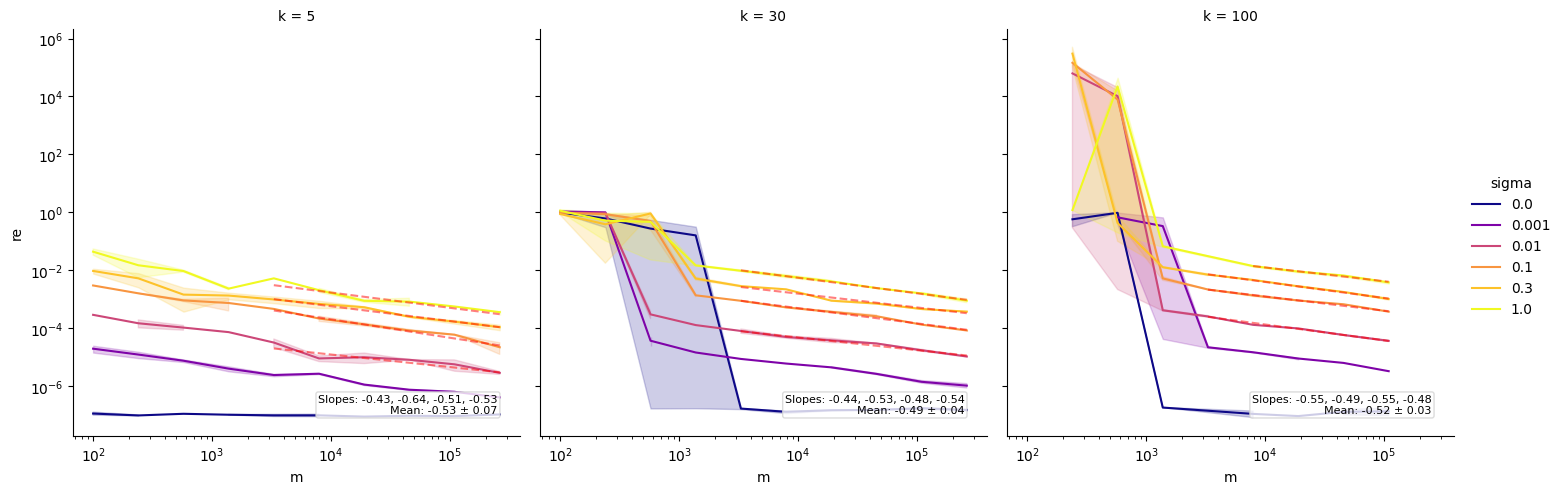

In [10]:
mydf = df[(df['adapted_sampling']==True)&(df['alg']=='bpdn_projected')]

fit_df = perform_least_squares_fit(
    mydf[mydf['sigma'] > 1e-3],
    x_col='m',
    y_col='re',
    group_cols=['k', 'sigma', 'alg', 'img', 'sampling_type', 'adapted_sampling'],
    min_x=10**3.2
)


# Create the main plot
g = sns.relplot(
    data=mydf,
    kind="line",
    x="m",
    y="re",
    col = 'k',
    hue="sigma",
    hue_norm=LogNorm(vmin=1e-4, clip=True),
    palette="plasma",
    errorbar="se"
)

g.set(xscale="log", yscale="log")

plot_on_facets(add_fit_lines_to_plot, g, fit_df, col_label="k", row_label="alg")

plt.show()
